First Five Rows:
    User ID  Gender  Age  EstimatedSalary  Purchased
0  15600000  Female   29            71630          1
1  15600001    Male   53            39872          1
2  15600002    Male   23            20794          0
3  15600003  Female   40           108161          1
4  15600004    Male   18           145128          0

Dataset Shape:
(400, 5)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   User ID          400 non-null    int64
 1   Gender           400 non-null    str  
 2   Age              400 non-null    int64
 3   EstimatedSalary  400 non-null    int64
 4   Purchased        400 non-null    int64
dtypes: int64(4), str(1)
memory usage: 17.7 KB
None

Missing Values:
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

Training Data: (300, 2)
Testing Data: (100, 2)

Pr

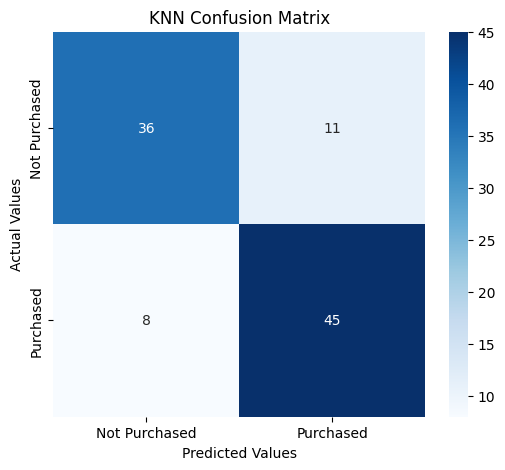

In [2]:
# Experiment: Classification using KNN Algorithm

# Step 1: Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report
)


# Step 2: Load Dataset

df = pd.read_csv("Social_Network_Ads.csv")

print("First Five Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())


# Step 3: Data Preprocessing

# Remove unnecessary columns

df.drop(
    columns=['User ID'],
    errors='ignore',
    inplace=True
)

# Convert Gender into numerical values

df['Gender'] = df['Gender'].map({
    'Male': 1,
    'Female': 0
})

# Check missing values

print("\nMissing Values:")
print(df.isnull().sum())

df.dropna(inplace=True)


# Step 4: Separate Independent and Dependent Variables

X = df[['Age', 'EstimatedSalary']]

y = df['Purchased']


# Step 5: Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


# Step 6: Feature Scaling

sc = StandardScaler()

X_train = sc.fit_transform(X_train)

X_test = sc.transform(X_test)


# Step 7: Implement KNN Algorithm

knn = KNeighborsClassifier(
    n_neighbors=5,
    metric='minkowski',
    p=2
)

# Train Model

knn.fit(X_train, y_train)


# Step 8: Predict Results

y_pred = knn.predict(X_test)

print("\nPredicted Values:")
print(y_pred)


# Step 9: Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)


# Step 10: Calculate Evaluation Metrics

accuracy = accuracy_score(y_test, y_pred)

error_rate = 1 - accuracy

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

print("\nEvaluation Metrics:")

print("Accuracy:", accuracy)

print("Error Rate:", error_rate)

print("Precision:", precision)

print("Recall:", recall)


# Step 11: Classification Report

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


# Step 12: Visualize Confusion Matrix

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Purchased', 'Purchased'],
    yticklabels=['Not Purchased', 'Purchased']
)

plt.title("KNN Confusion Matrix")

plt.xlabel("Predicted Values")

plt.ylabel("Actual Values")

plt.show()